In [1]:
SEED = 42
import torch
torch.set_grad_enabled(False)

torch.autograd.grad_mode.set_grad_enabled(mode=False)

In [2]:
from pathlib import Path
import sys

# Find the project root from the notebook's working directory.
PROJECT_ROOT = Path.cwd().resolve()

# Run until found the (PROJECT_ROOT / "requirements.txt")
while not (PROJECT_ROOT / "requirements.txt").is_file():
    if PROJECT_ROOT == PROJECT_ROOT.parent:
        raise RuntimeError("Cannot find the project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Allow imports starting with "src".
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data" / "raw"

In [3]:
import numpy as np
import time
from src.preprocessing.scaler import split_val, scale_flat 

train_data = np.load(DATA_DIR / "mnist_train.npz")
test_data = np.load(DATA_DIR / "mnist_test.npz")

X_train, y_train = train_data["X"], train_data["y"]
X_test, y_test = test_data["X"], test_data["y"]

In [4]:
X_train, X_val, y_train, y_val = split_val(X=X_train,y=y_train, val_size=0.1, seed=SEED)
X_train, X_val, X_test,tools = scale_flat(X_train=X_train, X_test=X_test, X_val=X_val, mode='raw')
print(f'Train: {len(X_train)}, Test: {len(X_test)}, Val: {len(X_val)}')

Train: 54000, Test: 10000, Val: 6000


In [5]:
from src.models.mlp import MLP
from src.models.logistic_regression import LogisticRegression
from src.models.naive_bayes import GaussianNaiveBayes
from src.evaluation.metrics import ClassificationMetrics

import matplotlib.pyplot as plt
import seaborn as sns

## TRAIN LOGISTIC REGRESSION

In [6]:
trained_models = {'model name' : [], 'models' : [], 'accuracy' : [], 'time train (s)': [], 'time pred (s)' : [], 'reports' : []}

In [7]:
model_lr = LogisticRegression(
    eta=0.2,
    lam= 0.001,
    max_epochs=100,
    batch_size=128,
    seed=42,
    tol=1e-7
)
start = time.perf_counter()
model_lr.fit(X_train, y_train)
time_lr_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_lr = model_lr.predict(X_test)
time_lr_pred = time.perf_counter() - start

metrics_lr = ClassificationMetrics(y_pred=y_pred_lr, y_true=y_test)
report_lr = metrics_lr.evaluate()

print(f"ACCURACY: {report_lr['accuracy']}, MACRO RECALL: {report_lr['macro_recall']}")
print(f"Thời gian huấn luyện LR: {time_lr_train:.3f} giây")
print(f"Thời gian dự đoán LR: {time_lr_pred:.3f} giây")


trained_models['model name'].append('Logistic Regression')
trained_models['models'].append(model_lr)
trained_models['accuracy'].append(report_lr['accuracy'])
trained_models['time train (s)'].append(f"{time_lr_train:.3f}")
trained_models['time pred (s)'].append(f"{time_lr_pred:.3f}")
trained_models['reports'].append(report_lr)

ACCURACY: 0.9187, MACRO RECALL: 0.9174064235367361
Thời gian huấn luyện LR: 21.040 giây
Thời gian dự đoán LR: 0.024 giây


## SOME VISUALIZATIONS OF LOGISTIC MODEL

In [8]:
def plot_confusion_matrix(
    cm,
    class_names,
    title="Confusion Matrix",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
    cmap="Blues",
    figsize=(10, 8),
):
    """Vẽ confusion matrix với hàng là nhãn thật, cột là nhãn dự đoán."""
    fig, ax = plt.subplots(figsize=figsize)

    sns.heatmap(
        cm,
        annot=True,
        fmt=".0f",
        cmap=cmap,
        xticklabels=class_names,
        yticklabels=class_names,
        linewidths=0.5,
        square=True,
        cbar_kws={"label": colorbar_label},
        ax=ax,
    )

    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)

    ax.tick_params(axis="x", labelrotation=0)
    ax.tick_params(axis="y", labelrotation=0)

    fig.tight_layout()
    plt.show()

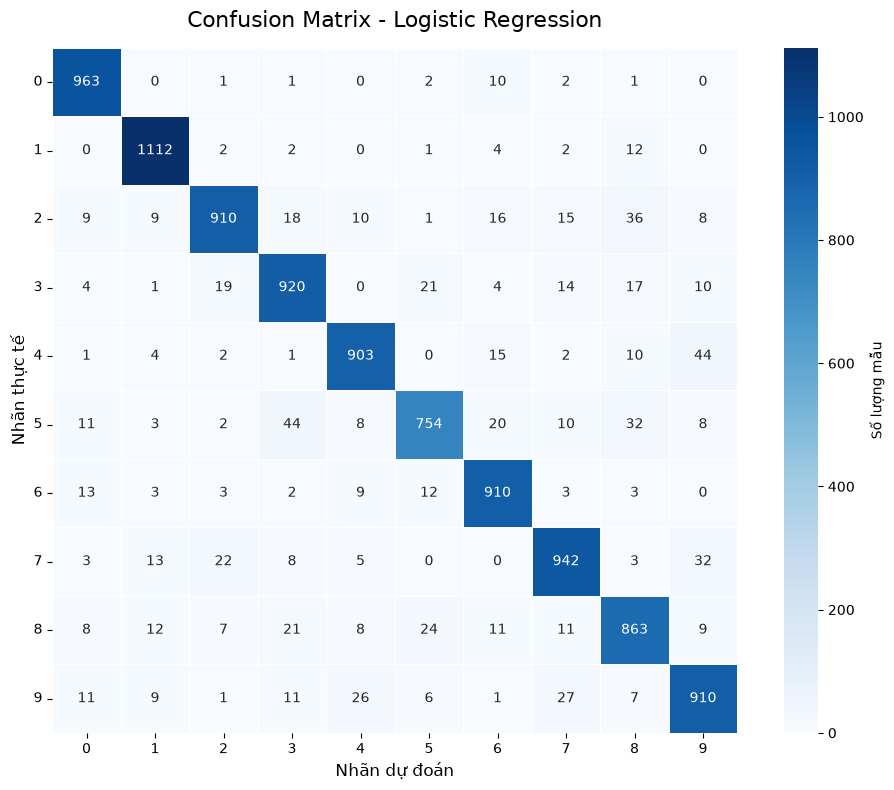

In [9]:
cm_lr, class_names = metrics_lr.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_lr,
    class_names=class_names,
    title="Confusion Matrix - Logistic Regression",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## TRAIN GAUSSIAN NAIVE BAYES

In [10]:
model_nb = GaussianNaiveBayes()

start = time.perf_counter()
model_nb.fit(X=X_train, y=y_train)
time_nb_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_nb = model_nb.predict(X_test)
time_nb_pred = time.perf_counter() - start


metrics_nb = ClassificationMetrics(y_pred=y_pred_nb, y_true=y_test)
report_nb = metrics_nb.evaluate()

print(report_nb['accuracy'], report_nb['macro_recall'])
print(f"Thời gian huấn luyện NB: {time_nb_train:.3f} giây")
print(f"Thời gian dự đoán NB: {time_nb_pred:.3f} giây")




trained_models['model name'].append('Naive Bayess')
trained_models['models'].append(model_nb)
trained_models['accuracy'].append(report_nb['accuracy'])
trained_models['time train (s)'].append(f"{time_nb_train:.3f}")
trained_models['time pred (s)'].append(f"{time_nb_pred:.3f}")
trained_models['reports'].append(report_nb)

0.5523 0.544894646835185
Thời gian huấn luyện NB: 0.771 giây
Thời gian dự đoán NB: 0.517 giây


## SOME VISUALIZATIONS OF GAUSSIAN NAIVE BAYESS

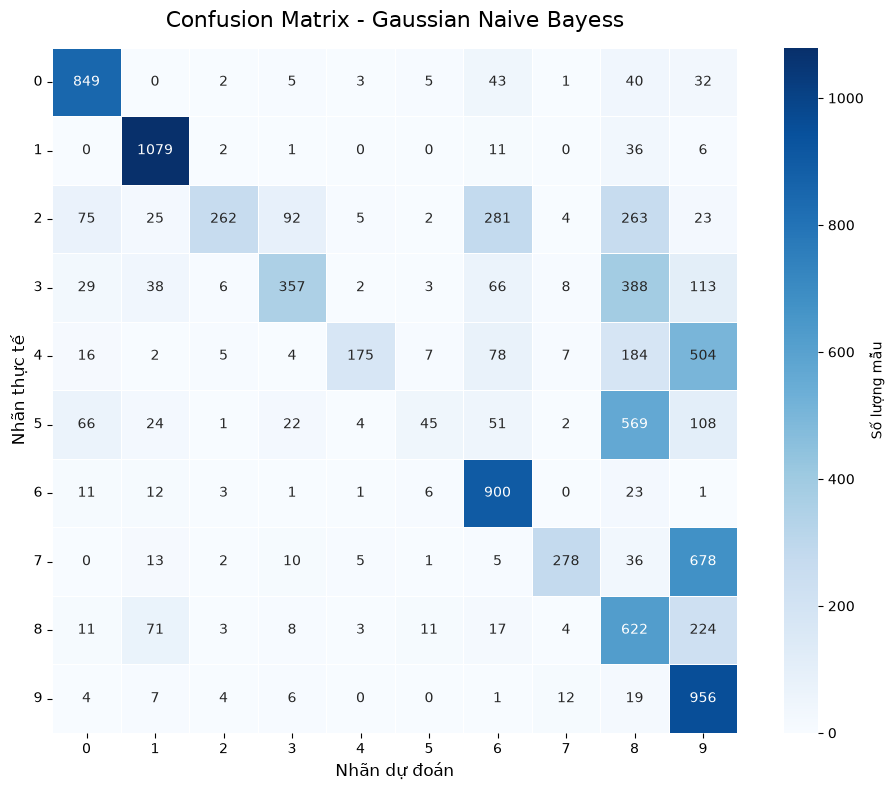

In [11]:
cm_nb, class_names_nb = metrics_nb.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_nb,
    class_names=class_names_nb,
    title="Confusion Matrix - Gaussian Naive Bayess",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## TRAIN MLP MODEL

In [12]:
model_mlp = MLP(
    sizes=(784, 500, 10),
    activation='relu',
    p_drop=0.2,
    init='he',
    seed=42,
)

start = time.perf_counter()
hist_mlp = model_mlp.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=9,
    batch_size=128,
    lr=0.08,
    patience = 4 # early stopping
)
time_mlp_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_mlp = model_mlp.predict(X_test)
time_mlp_pred = time.perf_counter() - start

metrics_mlp = ClassificationMetrics(y_pred=y_pred_mlp, y_true=y_test)
report_mlp = metrics_mlp.evaluate()

print(report_mlp['accuracy'], report_mlp['macro_recall'])
print(f"Time Train LR: {time_mlp_train}")
print(f"Time Test LR: {time_mlp_pred}")


trained_models['model name'].append('MLP')
trained_models['models'].append(model_mlp)
trained_models['accuracy'].append(report_mlp['accuracy'])
trained_models['time train (s)'].append(f"{time_mlp_train:.3f}")
trained_models['time pred (s)'].append(f"{time_mlp_pred:.3f}")
trained_models['reports'].append(report_mlp)

Epoch 01/09 | train loss 0.1220 acc 0.9627 | val loss 0.1467 acc 0.9560
Epoch 02/09 | train loss 0.0717 acc 0.9790 | val loss 0.1079 acc 0.9697
Epoch 03/09 | train loss 0.0487 acc 0.9864 | val loss 0.0883 acc 0.9750
Epoch 04/09 | train loss 0.0424 acc 0.9876 | val loss 0.0868 acc 0.9772
Epoch 05/09 | train loss 0.0301 acc 0.9916 | val loss 0.0781 acc 0.9770
Epoch 06/09 | train loss 0.0243 acc 0.9936 | val loss 0.0758 acc 0.9793
Epoch 07/09 | train loss 0.0182 acc 0.9957 | val loss 0.0724 acc 0.9810
Epoch 08/09 | train loss 0.0154 acc 0.9962 | val loss 0.0726 acc 0.9790
Epoch 09/09 | train loss 0.0124 acc 0.9973 | val loss 0.0700 acc 0.9810
0.9819 0.9818667674298274
Time Train LR: 13.344184950001363
Time Test LR: 0.031247223996615503


## VISUALIZE HISTORY OF MLP MODEL

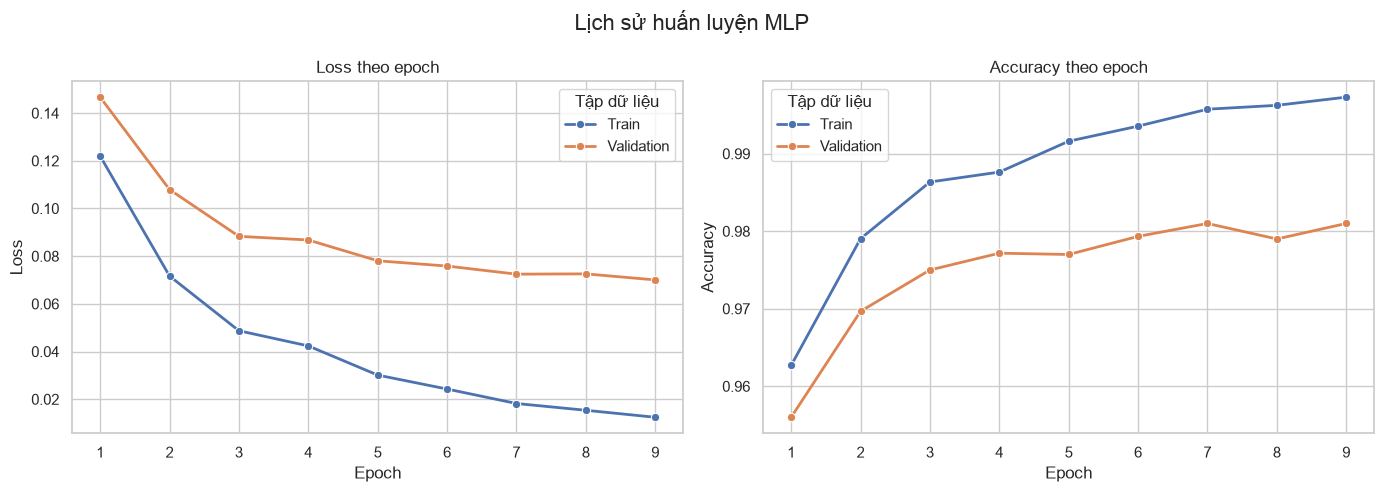

In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_training_history(history):
    """Vẽ loss và accuracy theo từng epoch."""
    sns.set_theme(style="whitegrid", context="notebook")

    history_df = pd.DataFrame(history)
    history_df["epoch"] = range(1, len(history_df) + 1)

    plot_configs = [
        ("train_loss", "val_loss", "Loss"),
        ("train_acc", "val_acc", "Accuracy"),
    ]

    fig, axes = plt.subplots(ncols=2, figsize=(14, 5))

    for ax, (train_key, val_key, metric) in zip(axes, plot_configs):
        plot_df = history_df.melt(
            id_vars="epoch",
            value_vars=[train_key, val_key],
            var_name="dataset",
            value_name="value",
        )
        plot_df["dataset"] = plot_df["dataset"].map(
            {
                train_key: "Train",
                val_key: "Validation",
            }
        )

        sns.lineplot(
            data=plot_df,
            x="epoch",
            y="value",
            hue="dataset",
            marker="o",
            linewidth=2,
            ax=ax,
        )

        ax.set(
            title=f"{metric} theo epoch",
            xlabel="Epoch",
            ylabel=metric,
            xticks=history_df["epoch"],
        )
        ax.legend(title="Tập dữ liệu")

    fig.suptitle("Lịch sử huấn luyện MLP", fontsize=16)
    fig.tight_layout()
    plt.show()


plot_training_history(hist_mlp)

In [14]:
print(f"Thời gian huấn luyện MLP: {time_mlp_train:.3f} giây")
print(f"Thời gian dự đoán MLP: {time_mlp_pred:.3f} giây")

Thời gian huấn luyện MLP: 13.344 giây
Thời gian dự đoán MLP: 0.031 giây


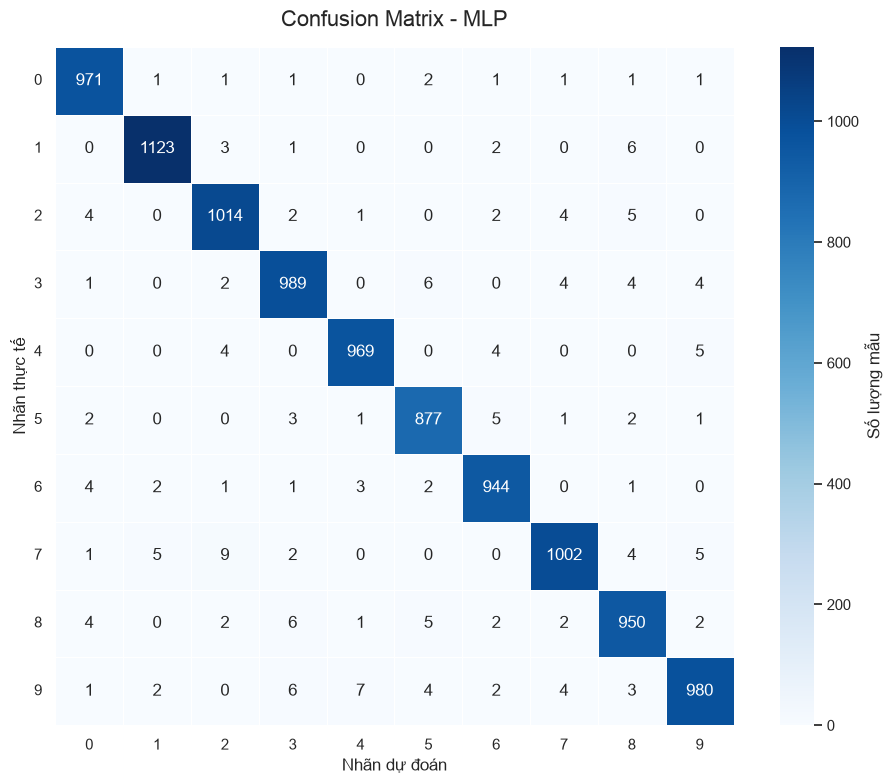

In [15]:
cm_mlp, class_names_mlp = metrics_mlp.get_confustion_matrix()

plot_confusion_matrix(
    cm=cm_mlp,
    class_names=class_names_mlp,
    title="Confusion Matrix - MLP",
    xlabel="Nhãn dự đoán",
    ylabel="Nhãn thực tế",
    colorbar_label="Số lượng mẫu",
)

## ĐO DIVERSITY VÀ BUILD ENSEMBLE MODEL

In [16]:
def measure_diversity(y_pred_1, y_pred_2, y_true):
    """Đo diversity giữa hai mô hình phân loại (theo slide 7 - tài liệu MNIST).

    Parameters
    ----------
    y_pred_1 : array-like, shape (n_samples,)
        Nhãn dự đoán của mô hình thứ nhất.
    y_pred_2 : array-like, shape (n_samples,)
        Nhãn dự đoán của mô hình thứ hai.
    y_true : array-like, shape (n_samples,)
        Nhãn thực tế.

    Returns
    -------
    dict
        disagreement: Tỷ lệ 2 mô hình dự đoán nhãn khác nhau (trên toàn bộ tập test).
        double_fault: Tỷ lệ CẢ HAI cùng sai TRÊN SỐ ẢNH CÓ ÍT NHẤT 1 MÔ HÌNH SAI.
    """
    y_pred_1 = np.asarray(y_pred_1)
    y_pred_2 = np.asarray(y_pred_2)
    y_true = np.asarray(y_true)

    # Xác định từng mô hình dự đoán đúng hay sai trên mỗi mẫu.
    correct_1 = y_pred_1 == y_true
    correct_2 = y_pred_2 == y_true

    # Số ảnh cả hai cùng sai
    both_wrong = int(np.sum(~correct_1 & ~correct_2))
    
    # Số ảnh có ít nhất 1 mô hình sai (theo công thức slide 7)
    at_least_one_wrong = int(np.sum(~correct_1 | ~correct_2))

    # Tỷ lệ hai mô hình dự đoán nhãn khác nhau (vẫn tính trên toàn bộ tập test)
    disagreement = float(np.mean(y_pred_1 != y_pred_2))

    # Tỷ lệ cả hai cùng sai TRÊN TẬP CÁC ẢNH CÓ ÍT NHẤT 1 MÔ HÌNH SAI
    # Đây là công thức trong slide 7
    if at_least_one_wrong == 0:
        double_fault = 0.0
    else:
        double_fault = both_wrong / at_least_one_wrong

    return {
        "disagreement": disagreement,
        "double_fault": double_fault,
        "both_wrong_count": both_wrong,
        "at_least_one_wrong_count": at_least_one_wrong,
    }

In [17]:
div_mlp_1 = measure_diversity(y_pred_lr, y_pred_mlp, y_test)
print(f"Double Fault: {div_mlp_1['double_fault']:.4f}")
print(f"Disagreement: {div_mlp_1['disagreement']:.4f}")
print(f"at_least_one_wrong_count : {div_mlp_1['at_least_one_wrong_count']}")
print(f"both_wrong_count: {div_mlp_1['both_wrong_count']}")

Double Fault: 0.1736
Disagreement: 0.0743
at_least_one_wrong_count : 847
both_wrong_count: 147


## NHẬN XÉT: LR vs MLP ENSEMBLE

### 1. Diversity CAO bất ngờ
- Double Fault = 18.48%
- Nguyên nhân có thể là do: LR (tuyến tính) và MLP (phi tuyến)

### 2. Nhưng ensemble có thể  không có lợi về accuracy
- LR quá yếu (92% acc) so với MLP (98% acc):
  - LR sai 800 ảnh, MLP chỉ sai 200 ảnh (test trên Test Size = 10000)
  - Trong 7.38% disagreement, đa số là "LR sai, MLP đúng"
  - không thể gánh được MLP hoàn toàn (cải thiệu acc 98 %), có khi còn kéo acc của MLP xuống thấp hơn 98% như đã đánh giá

- Ta nên chọn ensemble với MLP, chọn partner có accuracy >= 96%:
  - Random Forest
  - kNN
  - CNN <br>
> **Bây giờ ta sẽ đi kiểm chứng**

---

## TRAIN ANORTHER MLP MODEL

In [18]:
model_mlp_2 = MLP(
    sizes=(784, 300, 10),
    activation='relu',
    p_drop=0.2,
    init='he',
    seed=42,
)

start = time.perf_counter()
hist_mlp_2 = model_mlp_2.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=7,
    batch_size=128,
    lr=0.08,
    patience = 4 # early stopping
)
time_mlp_train_2 = time.perf_counter() - start

start = time.perf_counter()
y_pred_mlp_2 = model_mlp_2.predict(X_test)
time_mlp_pred_2 = time.perf_counter() - start

metrics_mlp_2 = ClassificationMetrics(y_pred=y_pred_mlp_2, y_true=y_test)
report_mlp_2 = metrics_mlp_2.evaluate()

print(f"Accuracy: {report_mlp_2['accuracy']}, Macro Recall: {report_mlp_2['macro_recall']}")
print(f"Time Train LR: {time_mlp_train_2}")
print(f"Time Test LR: {time_mlp_pred_2}")

Epoch 01/07 | train loss 0.1253 acc 0.9617 | val loss 0.1514 acc 0.9553
Epoch 02/07 | train loss 0.0808 acc 0.9758 | val loss 0.1144 acc 0.9653
Epoch 03/07 | train loss 0.0574 acc 0.9832 | val loss 0.0991 acc 0.9730
Epoch 04/07 | train loss 0.0441 acc 0.9866 | val loss 0.0894 acc 0.9740
Epoch 05/07 | train loss 0.0375 acc 0.9893 | val loss 0.0839 acc 0.9748
Epoch 06/07 | train loss 0.0308 acc 0.9914 | val loss 0.0815 acc 0.9762
Epoch 07/07 | train loss 0.0213 acc 0.9941 | val loss 0.0742 acc 0.9787
Accuracy: 0.9796, Macro Recall: 0.9794746383749772
Time Train LR: 6.704360797004483
Time Test LR: 0.0203828119992977


In [19]:
div = measure_diversity(y_pred_mlp_2, y_pred_mlp, y_test)
print(f"Double Fault: {div['double_fault']:.4f}")
print(f"Disagreement: {div['disagreement']:.4f}")
print(f"at_least_one_wrong_count : {div['at_least_one_wrong_count']}")
print(f"both_wrong_count: {div['both_wrong_count']}")

Double Fault: 0.5462
Disagreement: 0.0133
at_least_one_wrong_count : 249
both_wrong_count: 136


- Diversity của 2 model này khác thấp (Double Default = 0.5516)

## TEST VỀ DIVERSITY CỦA CÁC MÔ HÌNH KHÁC

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
trained_models_en = {'model name' : [], 'models' : [], 'accuracy' : [], 'time train (s)': [], 'time pred (s)' : [], 'reports' : []}

TRAIN TỪNG MÔ HÌNH RIÊNG LẺ

[1/3] Training MLP (784 -> 500 -> 10)...


<>:60: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
<>:60: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
/tmp/ipykernel_54443/1957257058.py:60: SyntaxWarning: "\H" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\H"? A raw string is also an option.
  print("\Hoàn tất training 3 mô hình.")


Epoch 01/09 | train loss 0.1220 acc 0.9627 | val loss 0.1467 acc 0.9560
Epoch 02/09 | train loss 0.0717 acc 0.9790 | val loss 0.1079 acc 0.9697
Epoch 03/09 | train loss 0.0487 acc 0.9864 | val loss 0.0883 acc 0.9750
Epoch 04/09 | train loss 0.0424 acc 0.9876 | val loss 0.0868 acc 0.9772
Epoch 05/09 | train loss 0.0301 acc 0.9916 | val loss 0.0781 acc 0.9770
Epoch 06/09 | train loss 0.0243 acc 0.9936 | val loss 0.0758 acc 0.9793
Epoch 07/09 | train loss 0.0182 acc 0.9957 | val loss 0.0724 acc 0.9810
Epoch 08/09 | train loss 0.0154 acc 0.9962 | val loss 0.0726 acc 0.9790
Epoch 09/09 | train loss 0.0124 acc 0.9973 | val loss 0.0700 acc 0.9810
[2/3] Training Random Forest...
[3/3] Training KNN...
\Hoàn tất training 3 mô hình.

ACCURACY TỪNG MÔ HÌNH
  MLP  | Accuracy: 0.9810 | Macro Recall: 0.9810
  RF   | Accuracy: 0.9672 | Macro Recall: 0.9670
  KNN  | Accuracy: 0.9723 | Macro Recall: 0.9719

ĐO DIVERSITY PAIRWISE
  MLP vs RF  | Double Fault: 0.3640 | Disagreement: 0.0270
  MLP vs KNN | D

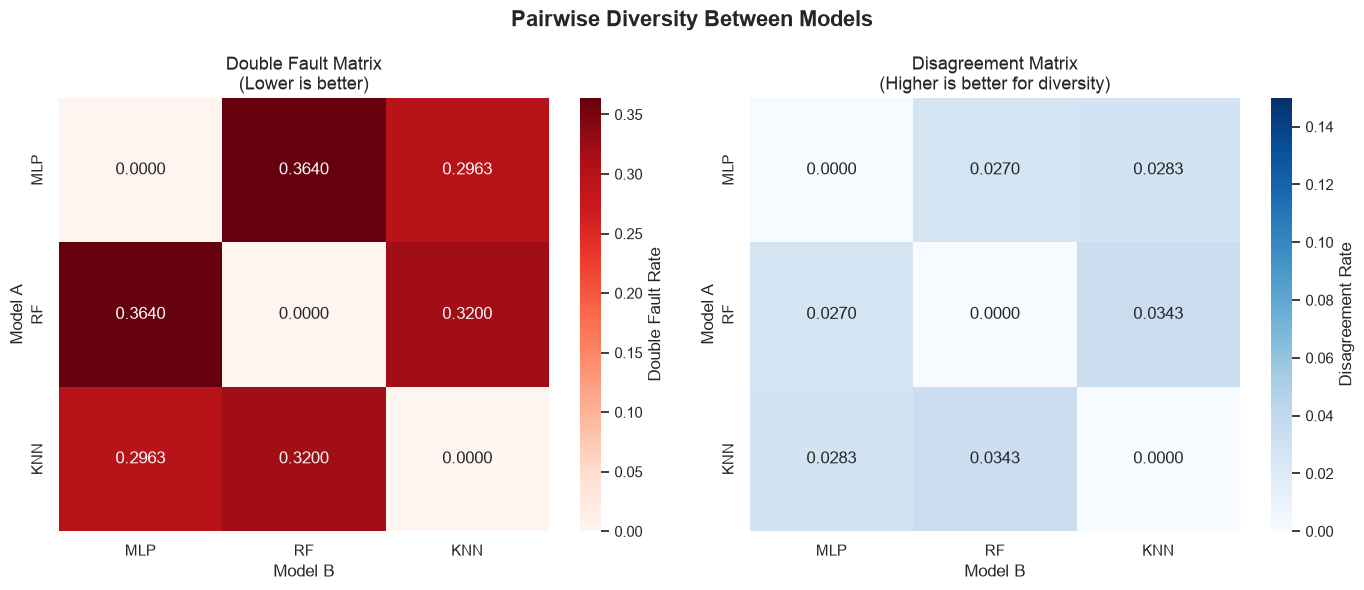

In [21]:
print("=" * 60)
print("TRAIN TỪNG MÔ HÌNH RIÊNG LẺ")
print("=" * 60)

# --- MLP ---
print("\n[1/3] Training MLP (784 -> 500 -> 10)...")
model_mlp_en = MLP(
    sizes=(784, 500, 10),
    activation='relu',
    p_drop=0.2,
    init='he',
    seed=42
)
start = time.perf_counter()
hist_mlp_en = model_mlp_en.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=9,
    batch_size=128,
    lr=0.08,
    patience=4,
)
time_mlp_train_en = time.perf_counter() - start

y_pred_mlp_en = model_mlp_en.predict(X_val)

# --- Random Forest ---
print("[2/3] Training Random Forest...")
model_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=None,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

start = time.perf_counter()
model_rf.fit(X_train, y_train)
time_rf_train = time.perf_counter() - start

y_pred_rf = model_rf.predict(X_val)

# --- KNN ---
print("[3/3] Training KNN...")
model_knn = KNeighborsClassifier(
    n_neighbors=3,
    weights='distance',
    metric='euclidean',
    n_jobs=-1
)

start = time.perf_counter()
model_knn.fit(X_train, y_train)
time_knn_train = time.perf_counter() - start

y_pred_knn = model_knn.predict(X_val)


print("\Hoàn tất training 3 mô hình.")


print("\n" + "=" * 60)
print("ACCURACY TỪNG MÔ HÌNH")
print("=" * 60)

models = {
    'MLP': (model_mlp_en, y_pred_mlp_en),
    'RF':  (model_rf,  y_pred_rf),
    'KNN': (model_knn, y_pred_knn)
}

trained_models_en['models'].append(model_mlp_en)
trained_models_en['models'].append(model_rf)
trained_models_en['models'].append(model_knn)
trained_models_en['time train (s)'].append(time_mlp_train_en)
trained_models_en['time train (s)'].append(time_rf_train)
trained_models_en['time train (s)'].append(time_knn_train)

for name, (_, y_pred) in models.items():
    metrics = ClassificationMetrics(y_pred=y_pred, y_true=y_val)
    report = metrics.evaluate()
    print(f"  {name:4s} | Accuracy: {report['accuracy']:.4f} | Macro Recall: {report['macro_recall']:.4f}")

# ĐO DIVERSITY PAIRWISE GIỮA CÁC MÔ HÌNH

print("\n" + "=" * 60)
print("ĐO DIVERSITY PAIRWISE")
print("=" * 60)

model_names = ['MLP', 'RF', 'KNN']
y_preds     = [y_pred_mlp_en, y_pred_rf, y_pred_knn]

n = len(model_names)
double_fault_mat   = np.zeros((n, n))
disagreement_mat   = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if i == j:
            double_fault_mat[i, j] = 0.0
            disagreement_mat[i, j] = 0.0
        else:
            div = measure_diversity(y_preds[i], y_preds[j], y_val)
            double_fault_mat[i, j] = div['double_fault']
            disagreement_mat[i, j] = div['disagreement']
            print(f"  {model_names[i]} vs {model_names[j]:3s} | "
                  f"Double Fault: {div['double_fault']:.4f} | "
                  f"Disagreement: {div['disagreement']:.4f}")


# VISUALIZE DIVERSITY MATRIX

print("\n" + "=" * 60)
print("VISUALIZE DIVERSITY")
print("=" * 60)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Pairwise Diversity Between Models", fontsize=16, fontweight='bold')

# --- Heatmap 1: Double Fault ---
sns.heatmap(
    double_fault_mat,
    annot=True,
    fmt='.4f',
    cmap='Reds',
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[0],
    cbar_kws={'label': 'Double Fault Rate'},
    vmin=0, vmax=max(double_fault_mat.max(), 0.05)
)
axes[0].set_title("Double Fault Matrix\n(Lower is better)", fontsize=13)
axes[0].set_xlabel("Model B")
axes[0].set_ylabel("Model A")

# --- Heatmap 2: Disagreement ---
sns.heatmap(
    disagreement_mat,
    annot=True,
    fmt='.4f',
    cmap='Blues',
    xticklabels=model_names,
    yticklabels=model_names,
    ax=axes[1],
    cbar_kws={'label': 'Disagreement Rate'},
    vmin=0, vmax=max(disagreement_mat.max(), 0.15)
)
axes[1].set_title("Disagreement Matrix\n(Higher is better for diversity)", fontsize=13)
axes[1].set_xlabel("Model B")
axes[1].set_ylabel("Model A")

plt.tight_layout()
plt.show()

## Dự đoán các model trên tập test hoàn toàn chưa đc nhìn thấy

In [22]:
start = time.perf_counter() 
y_pred_mlp_en = models['MLP'][0].predict(X_test)
time_mlp_pred = time.perf_counter() - start

start = time.perf_counter() 
y_pred_rf = models['RF'][0].predict(X_test)
time_rf_pred = time.perf_counter() - start

start = time.perf_counter() 
y_pred_knn = models['KNN'][0].predict(X_test)
time_knn_pred = time.perf_counter() - start

dict_models = {
    'MLP' : y_pred_mlp_en,
    'RF': y_pred_rf,
    'KNN': y_pred_knn
}

trained_models_en['time pred (s)'].append(time_mlp_pred)
trained_models_en['time pred (s)'].append(time_rf_pred)
trained_models_en['time pred (s)'].append(time_knn_pred)

for name, (y_pred) in dict_models.items():
    metrics = ClassificationMetrics(y_pred=y_pred, y_true=y_test)
    report = metrics.evaluate()
    print(f"  {name:4s} | Accuracy: {report['accuracy']:.4f} | Macro Recall: {report['macro_recall']:.4f}")

    trained_models_en['accuracy'].append(report['accuracy'])
    trained_models_en['reports'].append(report)
    trained_models_en['model name'].append(name)

  MLP  | Accuracy: 0.9819 | Macro Recall: 0.9819
  RF   | Accuracy: 0.9688 | Macro Recall: 0.9685
  KNN  | Accuracy: 0.9709 | Macro Recall: 0.9706


### Kết luận & Đánh giá Diversity

* **Tổng quan:** Ba mô hình (MLP, RF, KNN) có tính đa dạng (diversity) đủ để ensemble có lợi. Các mô hình có những lỗi khác nhau, cho thấy tiềm năng bù trừ lỗi. Hiệu quả kết hợp được kiểm chứng bằng accuracy trên validation.
* **Cặp đôi tốt nhất:** **MLP vs KNN** có chỉ số trùng lỗi thấp nhất (`Double Fault = 30.05%`), cho thấy khả năng bù trừ lỗi cho nhau tốt nhất.
* **Cặp trùng lỗi nhiều nhất:** **RF vs MLP** (`Double Fault = 34.73%`), do cả hai đều có xu hướng sai ở những vùng dữ liệu khó tương tự nhau.
* **Hiệu quả Ensemble:** Việc kết hợp `RF + KNN + MLP` là một phương án hợp lý để cải thiện về accuracy.

## SỬ DỤNG SOFT VOTTING RANDOM FOREST + KNN + MLP (cấu hình đầu tiên)
- Từ thí nghiệm trên, cho thấy sự kết hợp giữa 3 models này có triển vọng trong việc cải thiện về accuracy.

In [23]:
class CustomSoftVotingEnsemble:
    """
    Lớp Ensemble Soft Voting tùy chỉnh.
    """
    def __init__(self, weights=None):
        """
        Args:
            mlp_model: Instance của mô hình MLP.
            weights: List trọng số [mlp_w, rf_w, knn_w].
        """
        self.mlp = MLP(
            sizes=(784, 500, 10),
            activation='relu',
            p_drop=0.2,
            init='he',
            seed=42
        )
        self.weights = np.asarray(
            [3, 1, 1] if weights is None else weights,
            dtype=float,
        )
        
        # Khởi tạo RF và KNN
        self.rf = RandomForestClassifier(
            n_estimators=200, max_depth=None, min_samples_split=5, 
            random_state=42, n_jobs=-1
        )
        self.knn = KNeighborsClassifier(
            n_neighbors=3, weights='distance', metric='euclidean', 
            n_jobs=-1
        )

    def fit(self, X_train, y_train, X_val, y_val, patience = 4):
        """Huấn luyện cả 3 mô hình: MLP, RF và KNN."""
        print("Đang train MLP...")
        self.mlp.fit(
            X_train,
            y_train,
            validation_data=(X_val, y_val),
            epochs=9,
            batch_size=128,
            lr=0.08,
            patience = patience # early stopping
        )
        print("Train xong mlp: sizes = (784, 500, 10), activation = relu, p_dropout = 0.2, init = he")
        print("Đang train Random Forest và KNN...")
        self.rf.fit(X_train, y_train)
        self.knn.fit(X_train, y_train)
        print(f"Train xong RF: {self.rf}")
        print(f"Train xong KNN: {self.knn}")
        print("Hoàn tất fitting toàn bộ Ensemble.")
        return self

    def predict_proba(self, X):
        """Tính trung bình có trọng số (weighted average) của xác suất."""
        # Lấy xác suất dự đoán từ từng mô hình
        proba_mlp = self.mlp.predict_proba(X)
        proba_rf = self.rf.predict_proba(X)
        proba_knn = self.knn.predict_proba(X)
        
        # Chuẩn hóa weights để tổng bằng 1
        norm_weights = np.array(self.weights) / sum(self.weights)
        
        # Soft voting: cộng dồn xác suất theo trọng số
        ensemble_proba = (
            norm_weights[0] * proba_mlp +
            norm_weights[1] * proba_rf +
            norm_weights[2] * proba_knn
        )
        return ensemble_proba

    def predict(self, X):
        """Dự đoán nhãn cuối cùng dựa trên xác suất cao nhất."""
        return np.argmax(self.predict_proba(X), axis=1)

In [24]:
ensemble = CustomSoftVotingEnsemble(
    weights=[2, 2, 1]
)

start = time.perf_counter()
ensemble.fit(X_train, y_train, X_val, y_val, patience=4)
time_ensemble_train = time.perf_counter() - start

start = time.perf_counter()
y_pred_ens = ensemble.predict(X_test)
time_ensemble_pred = time.perf_counter() - start

metrics_ens = ClassificationMetrics(y_pred=y_pred_ens, y_true=y_test)
report_ens = metrics_ens.evaluate()

trained_models_en['models'].append(ensemble)
trained_models_en['model name'].append('Ensemble (MLP + RF + KNN)')
trained_models_en['accuracy'].append(report_ens['accuracy'])
trained_models_en['reports'].append(report_ens)
trained_models_en['time train (s)'].append(time_ensemble_train)
trained_models_en['time pred (s)'].append(time_ensemble_pred)

Đang train MLP...
Epoch 01/09 | train loss 0.1220 acc 0.9627 | val loss 0.1467 acc 0.9560
Epoch 02/09 | train loss 0.0717 acc 0.9790 | val loss 0.1079 acc 0.9697
Epoch 03/09 | train loss 0.0487 acc 0.9864 | val loss 0.0883 acc 0.9750
Epoch 04/09 | train loss 0.0424 acc 0.9876 | val loss 0.0868 acc 0.9772
Epoch 05/09 | train loss 0.0301 acc 0.9916 | val loss 0.0781 acc 0.9770
Epoch 06/09 | train loss 0.0243 acc 0.9936 | val loss 0.0758 acc 0.9793
Epoch 07/09 | train loss 0.0182 acc 0.9957 | val loss 0.0724 acc 0.9810
Epoch 08/09 | train loss 0.0154 acc 0.9962 | val loss 0.0726 acc 0.9790
Epoch 09/09 | train loss 0.0124 acc 0.9973 | val loss 0.0700 acc 0.9810
Train xong mlp: sizes = (784, 500, 10), activation = relu, p_dropout = 0.2, init = he
Đang train Random Forest và KNN...
Train xong RF: RandomForestClassifier(min_samples_split=5, n_estimators=200, n_jobs=-1,
                       random_state=42)
Train xong KNN: KNeighborsClassifier(metric='euclidean', n_jobs=-1, n_neighbors=3,
  

/tmp/ipykernel_54443/1705406151.py:66: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  norm_weights[0] * proba_mlp +


In [25]:
print(f"Ensemble Accuracy : {report_ens['accuracy']:.4f}")
print(f"Macro Recall      : {report_ens['macro_recall']:.4f}")
print(f"Time Train: {time_ensemble_train}")
print(f"Time Test: {time_ensemble_pred}")

Ensemble Accuracy : 0.9845
Macro Recall      : 0.9845
Time Train: 24.41680594599893
Time Test: 6.068360083001608


In [26]:
from IPython.display import display

def show_results(data):
    df = pd.DataFrame({
        "Mô hình": data["model name"],
        "Accuracy": data["accuracy"],
        "Macro Recall": [r["macro_recall"] for r in data["reports"]],
        "Macro F1": [r["macro_f1"] for r in data["reports"]],
        "Train (s)": data["time train (s)"],
        "Predict (s)": data["time pred (s)"],
    })

    metrics = ["Accuracy", "Macro Recall", "Macro F1"]
    times = ["Train (s)", "Predict (s)"]

    df[metrics + times] = df[metrics + times].astype(float)
    df = df.sort_values("Accuracy", ascending=False)

    display(
        df.style
        .hide(axis="index")
        .format({
            **{col: "{:.2%}" for col in metrics},
            **{col: "{:.3f}" for col in times},
        })
        .highlight_max(subset=metrics, color="#166534")
        .highlight_min(subset=times, color="#166534")
    )

In [27]:
len(trained_models_en['accuracy']), len(trained_models['accuracy'])


(4, 3)

In [28]:
show_results(trained_models_en)

Mô hình,Accuracy,Macro Recall,Macro F1,Train (s),Predict (s)
Ensemble (MLP + RF + KNN),98.45%,98.45%,98.45%,24.417,6.068
MLP,98.19%,98.19%,98.18%,13.915,0.043
KNN,97.09%,97.06%,97.07%,0.014,5.739
RF,96.88%,96.85%,96.85%,10.274,0.192


In [29]:
show_results(trained_models)

Mô hình,Accuracy,Macro Recall,Macro F1,Train (s),Predict (s)
MLP,98.19%,98.19%,98.18%,13.344,0.031
Logistic Regression,91.87%,91.74%,91.75%,21.040,0.024
Naive Bayess,55.23%,54.49%,50.63%,0.771,0.517


## LƯU TRỌNG SỐ CỦA CÁC MÔ HÌNH

In [30]:
from pathlib import Path
import sys
import torch
import joblib
import json

## LƯU MODEL

In [31]:
# Thiết lập đường dẫn thư mục models tại thư mục gốc hiện tại
MODELS_DIR = PROJECT_ROOT / 'models'
MODELS_DIR.mkdir(parents=True, exist_ok=True)  # Tự động tạo thư mục nếu chưa tồn tại

print(f"Đang lưu mô hình vào thư mục: {MODELS_DIR.absolute()}")

# LƯU MÔ HÌNH MLP (PyTorch Custom)
mlp_save_path = MODELS_DIR / "mlp_model.pth"

mlp_checkpoint = {
    'model_state_dict': model_mlp.model.state_dict(),
    'config': {
        'sizes': model_mlp.sizes,
        'activation': 'relu',
        'p_drop': 0.2,
        'init': 'he',
        'seed': 42
    },
    'history': model_mlp.history_,
    'best_epoch': getattr(model_mlp, 'best_epoch_', None)
}

torch.save(mlp_checkpoint, mlp_save_path)
print(f"Đã lưu MLP tại: {mlp_save_path}")

# LƯU MÔ HÌNH ENSEMBLE
if 'ensemble' in locals():
    ens_dir = MODELS_DIR / "ensemble_v1"
    ens_dir.mkdir(exist_ok=True)  # Tạo thư mục con ensemble_v1
    
    # Lưu MLP trong ensemble
    torch.save({
        'model_state_dict': ensemble.mlp.model.state_dict(),
        'config': {'sizes': ensemble.mlp.sizes, 'activation': 'relu', 'p_drop': 0.2, 'init': 'he'}
    }, ens_dir / "mlp_part.pth")
    
    # Lưu RF và KNN bằng joblib
    joblib.dump(ensemble.rf, ens_dir / "rf_part.joblib")
    joblib.dump(ensemble.knn, ens_dir / "knn_part.joblib")
    
    # Lưu weights voting
    with open(ens_dir / "config.json", "w") as f:
        # Chuyển numpy array sang list thường để json lưu được
        json.dump({"weights": ensemble.weights.tolist()}, f)
        
    print(f"Đã lưu Ensemble tại thư mục: {ens_dir}/")

# LƯU LOGISTIC REGRESSION & NAIVE BAYES (Sklearn)
if 'model_lr' in locals():
    lr_path = MODELS_DIR / "logistic_regression.joblib"
    joblib.dump(model_lr, lr_path)
    print(f"Đã lưu Logistic Regression tại: {lr_path}")

if 'model_nb' in locals():
    nb_path = MODELS_DIR / "naive_bayes.joblib"
    joblib.dump(model_nb, nb_path)
    print(f"Đã lưu Naive Bayes tại: {nb_path}")

print("\nHOÀN TẤT LƯU TRỮ!")

Đang lưu mô hình vào thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models
Đã lưu MLP tại: /home/nguyenhaianh/Desktop/Classify_Number/models/mlp_model.pth
Đã lưu Ensemble tại thư mục: /home/nguyenhaianh/Desktop/Classify_Number/models/ensemble_v1/
Đã lưu Logistic Regression tại: /home/nguyenhaianh/Desktop/Classify_Number/models/logistic_regression.joblib
Đã lưu Naive Bayes tại: /home/nguyenhaianh/Desktop/Classify_Number/models/naive_bayes.joblib

HOÀN TẤT LƯU TRỮ!
